# lee: examples and feature checks

This notebook walks through every class in `lee` and checks each feature against an independent reference: `scipy.linalg.expm`, finite differences, or a matrix identity. Every check is an `assert`, so the notebook stops at the first failure.

Requirements: `pip install lee-groups` (see the README) plus `scipy` and `matplotlib` for the reference checks and the plot, e.g. `pip install "lee-groups[examples]"`.

In [1]:
import numpy as np
from scipy.linalg import expm
import lee
from lee import SO_n, so_n, se3, SE3, se2, SE2, to_hat, to_vee

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)

def check(name, ok):
    assert ok, name
    print("ok  ", name)

## 1. hat and vee

`to_hat` turns a vector into a skew-symmetric matrix, and `to_vee` turns it back. For a 3-vector, `to_hat(w) @ v` is the cross product `w × v`. For a 1-vector it gives the 2×2 generator of SO(2).

In [2]:
w = np.array([0.1, -0.4, 0.7])
v = rng.normal(size=3)
W = to_hat(w)
print(W)
check("to_hat(w) is skew-symmetric", np.allclose(W, -W.T))
check("to_hat(w) @ v equals the cross product", np.allclose(W @ v, np.cross(w, v)))
check("to_vee(to_hat(w)) == w", np.allclose(to_vee(W), w))
check("1-vector gives the SO(2) generator", np.allclose(to_hat(np.array([0.3])), [[0, -0.3], [0.3, 0]]))

[[ 0.  -0.7 -0.4]
 [ 0.7  0.  -0.1]
 [ 0.4  0.1  0. ]]
ok   to_hat(w) is skew-symmetric
ok   to_hat(w) @ v equals the cross product
ok   to_vee(to_hat(w)) == w
ok   1-vector gives the SO(2) generator


## 2. SO_n (rotations) and so_n (rotation vectors)

`so_n(phi)` is a rotation vector, an element of the Lie algebra so(3) (or so(2) for a 1-vector). `exp_map()` turns it into an `SO_n` rotation (Rodrigues' formula). `SO_n(R).log_map()` goes back. Near θ = 0 and θ = π, both use special-case formulas, so they stay accurate there.

In [3]:
phi = np.array([0.3, -0.2, 0.9])
r = so_n(phi)
R = r.exp_map()
print("theta =", r.theta)
print(R.R)
check("Exp matches scipy expm", np.allclose(R.R, expm(r.hat)))
check("result is a rotation (R R^T = I, det = 1)", np.allclose(R.R @ R.R.T, np.eye(3)) and np.isclose(np.linalg.det(R.R), 1))
check("Log(Exp(phi)) == phi", np.allclose(R.log_map().vee, phi))
check("inverse() is the transpose", np.allclose(R.inverse(), R.R.T))

for theta in [0.0, 1e-8, 1e-4, 1.0, 3.0, np.pi - 1e-6]:
    a = rng.normal(size=3); p = theta * a / np.linalg.norm(a)
    check(f"Log(Exp(phi)) round trip at theta = {theta:.2e}", np.allclose(so_n(p).exp_map().log_map().vee, p, atol=1e-6))

try:
    SO_n(np.diag([1.0, 1.0, -1.0]))
except ValueError as e:
    print("ok   a reflection is rejected:", e)

R2 = so_n(np.array([0.7])).exp_map()
print(R2.R)
check("SO(2): Exp then Log gives the angle back", np.isclose(R2.log_map().vee[0], 0.7))

theta = 0.9695359714832659
[[ 0.6073 -0.7932 -0.0454]
 [ 0.7378  0.5842 -0.3383]
 [ 0.2949  0.172   0.9399]]
ok   Exp matches scipy expm
ok   result is a rotation (R R^T = I, det = 1)
ok   Log(Exp(phi)) == phi
ok   inverse() is the transpose
ok   Log(Exp(phi)) round trip at theta = 0.00e+00
ok   Log(Exp(phi)) round trip at theta = 1.00e-08
ok   Log(Exp(phi)) round trip at theta = 1.00e-04
ok   Log(Exp(phi)) round trip at theta = 1.00e+00
ok   Log(Exp(phi)) round trip at theta = 3.00e+00
ok   Log(Exp(phi)) round trip at theta = 3.14e+00
ok   a reflection is rejected: Invalid rotation matrix
[[ 0.7648 -0.6442]
 [ 0.6442  0.7648]]
ok   SO(2): Exp then Log gives the angle back


### Jacobians of SO(3)

`compute_left_jacobians()` returns `(J_l, J_l^{-1})`; `compute_left_jacobians(right=True)` returns `(J_r, J_r^{-1})`. They describe how a small change in the rotation vector moves the rotation:

- left: `Exp(phi + d) ≈ Exp(J_l d) Exp(phi)`
- right: `Exp(phi + d) ≈ Exp(phi) Exp(J_r d)`

In [4]:
Jl, Jl_inv = r.compute_left_jacobians()
Jr, Jr_inv = r.compute_left_jacobians(right=True)
check("J_l @ J_l^-1 == I", np.allclose(Jl @ Jl_inv, np.eye(3)))
check("J_r @ J_r^-1 == I", np.allclose(Jr @ Jr_inv, np.eye(3)))
check("J_r(phi) == J_l(-phi)", np.allclose(Jr, so_n(-phi).compute_left_jacobians()[0]))

d = 1e-6 * rng.normal(size=3)
lhs = so_n(phi + d).exp_map().R
check("left Jacobian:  Exp(phi + d) ≈ Exp(J_l d) Exp(phi)", np.allclose(lhs, so_n(Jl @ d).exp_map().R @ R.R, atol=1e-11))
check("right Jacobian: Exp(phi + d) ≈ Exp(phi) Exp(J_r d)", np.allclose(lhs, R.R @ so_n(Jr @ d).exp_map().R, atol=1e-11))

ok   J_l @ J_l^-1 == I
ok   J_r @ J_r^-1 == I
ok   J_r(phi) == J_l(-phi)
ok   left Jacobian:  Exp(phi + d) ≈ Exp(J_l d) Exp(phi)
ok   right Jacobian: Exp(phi + d) ≈ Exp(phi) Exp(J_r d)


## 3. se3 (twists) and SE3 (3-D poses)

A twist is a 6-vector **ξ = (ρ, φ), translation first**. `se3(xi).exp_map()` gives an `SE3` pose and `SE3.Log()` goes back. A pose can be built from an `SO_n` rotation or from a unit quaternion **(x, y, z, w)**, scalar last (the g2o / ROS / scipy order). Translations are numpy arrays.

In [5]:
xi = np.array([1.0, -0.5, 0.2, 0.3, -0.2, 0.9])
tw = se3(xi)
T = tw.exp_map()
print(T.X)
check("Exp matches scipy expm", np.allclose(T.X, expm(tw.hat)))
check("Log(Exp(xi)) == xi", np.allclose(T.Log(), xi))
eta = rng.normal(size=6)
Mb = tw.hat @ se3(eta).hat - se3(eta).hat @ tw.hat
check("ad(xi) @ eta == vee of the commutator [xi^, eta^]", np.allclose(tw.ad() @ eta, np.concatenate([Mb[:3, 3], to_vee(Mb[:3, :3])])))

q = np.array([0.1, -0.2, 0.3, 0.9]); q = q / np.linalg.norm(q)
Tq = SE3(q, np.array([1.0, 2.0, 3.0]))
x, y, z, w_ = q
R_ref = np.array([[1 - 2*(y*y + z*z), 2*(x*y - z*w_), 2*(x*z + y*w_)],
                  [2*(x*y + z*w_), 1 - 2*(x*x + z*z), 2*(y*z - x*w_)],
                  [2*(x*z - y*w_), 2*(y*z + x*w_), 1 - 2*(x*x + y*y)]])
check("pose from a quaternion (x, y, z, w)", np.allclose(Tq.R, R_ref) and np.allclose(Tq.t_flat, [1, 2, 3]))
check("q and -q give the same pose", np.allclose(SE3(-q, np.array([1.0, 2.0, 3.0])).X, Tq.X))

[[ 0.6073 -0.7932 -0.0454  1.0676]
 [ 0.7378  0.5842 -0.3383 -0.0556]
 [ 0.2949  0.172   0.9399  0.2762]
 [ 0.      0.      0.      1.    ]]
ok   Exp matches scipy expm
ok   Log(Exp(xi)) == xi
ok   ad(xi) @ eta == vee of the commutator [xi^, eta^]
ok   pose from a quaternion (x, y, z, w)
ok   q and -q give the same pose


In [6]:
U = se3(np.array([0.2, 0.1, -0.3, -0.5, 0.4, 0.1])).exp_map()
p = rng.normal(size=3)
P = rng.normal(size=(3, 5))

check("T @ U composes poses", np.allclose((T @ U).X, T.X @ U.X))
check("T @ p transforms a point", np.allclose(T @ p, (T.X @ np.append(p, 1))[:3]))
check("T @ P transforms a (3, N) cloud", np.allclose(T @ P, (T.X @ np.vstack([P, np.ones(5)]))[:3]))
check("inverse() is the 4x4 inverse", np.allclose(T.inverse(), np.linalg.inv(T.X)))
check("T @ T.inverse_pose() is the identity", np.allclose((T @ T.inverse_pose()).X, np.eye(4)))

d = np.array([0.05, -0.02, 0.01, 0.03, 0.02, -0.04])
check("boxplus: T ⊞ d == T Exp(d)", np.allclose(T.boxplus(d).X, T.X @ expm(se3(d).hat)))
check("boxminus undoes boxplus", np.allclose(T.boxplus(d).boxminus(T), d))
check("T ⊞ (U ⊟ T) == U", np.allclose(T.boxplus(U.boxminus(T)).X, U.X))

check("Ad identity: T Exp(d) T^-1 == Exp(Ad_T d)", np.allclose(T.X @ expm(se3(d).hat) @ T.inverse(), expm(se3(T.Ad() @ d).hat)))
check("Ad_inv is the inverse of Ad", np.allclose(T.Ad_inv(), np.linalg.inv(T.Ad())))

ok   T @ U composes poses
ok   T @ p transforms a point
ok   T @ P transforms a (3, N) cloud
ok   inverse() is the 4x4 inverse
ok   T @ T.inverse_pose() is the identity
ok   boxplus: T ⊞ d == T Exp(d)
ok   boxminus undoes boxplus
ok   T ⊞ (U ⊟ T) == U
ok   Ad identity: T Exp(d) T^-1 == Exp(Ad_T d)
ok   Ad_inv is the inverse of Ad


In [7]:
Jl, Jl_inv = tw.compute_left_jacobians()
Jr, Jr_inv = tw.compute_left_jacobians(right=True)
check("SE(3): J_l @ J_l^-1 == I", np.allclose(Jl @ Jl_inv, np.eye(6)))
check("SE(3): J_r @ J_r^-1 == I", np.allclose(Jr @ Jr_inv, np.eye(6)))
d = 1e-6 * rng.normal(size=6)
lhs = se3(xi + d).exp_map().X
check("SE(3) right Jacobian: Exp(xi + d) ≈ Exp(xi) Exp(J_r d)", np.allclose(lhs, T.X @ se3(Jr @ d).exp_map().X, atol=1e-11))
check("SE(3) left Jacobian:  Exp(xi + d) ≈ Exp(J_l d) Exp(xi)", np.allclose(lhs, se3(Jl @ d).exp_map().X @ T.X, atol=1e-11))

ok   SE(3): J_l @ J_l^-1 == I
ok   SE(3): J_r @ J_r^-1 == I
ok   SE(3) right Jacobian: Exp(xi + d) ≈ Exp(xi) Exp(J_r d)
ok   SE(3) left Jacobian:  Exp(xi + d) ≈ Exp(J_l d) Exp(xi)


## 4. se2 (2-D twists) and SE2 (2-D poses)

The same interface in 2-D. A twist is **(x, y, θ)**, and a pose can be built from an angle or an `SO_n` 2×2 rotation.

In [8]:
xi2 = np.array([1.0, -0.5, 0.8])
tw2 = se2(xi2)
T2 = tw2.exp_map()
print(T2.X, "theta =", T2.theta)
check("SE(2) Exp matches scipy expm", np.allclose(T2.X, expm(tw2.hat)))
check("SE(2) Log(Exp(xi)) == xi", np.allclose(T2.Log(), xi2))
check("pose from an angle", np.allclose(SE2(0.8, np.array([1.0, 2.0])).R, [[np.cos(0.8), -np.sin(0.8)], [np.sin(0.8), np.cos(0.8)]]))
check("theta = pi round trip", np.isclose(SE2(np.pi, np.zeros(2)).Log()[2], np.pi))

U2 = SE2(-2.0, np.array([0.3, 0.7]))
d2 = np.array([0.05, -0.03, 0.02])
check("SE(2) composition", np.allclose((T2 @ U2).X, T2.X @ U2.X))
check("SE(2) point transform", np.allclose(T2 @ np.array([1.0, 2.0]), (T2.X @ [1, 2, 1])[:2]))
check("SE(2) T @ T.inverse_pose() is the identity", np.allclose((T2 @ T2.inverse_pose()).X, np.eye(3)))
check("SE(2) boxminus undoes boxplus", np.allclose(T2.boxplus(d2).boxminus(T2), d2))
check("SE(2) Ad identity", np.allclose(T2.X @ expm(se2(d2).hat) @ T2.inverse(), expm(se2(T2.Ad() @ d2).hat)))

Jr2, Jr2_inv = tw2.compute_left_jacobians(right=True)
check("SE(2): J_r @ J_r^-1 == I", np.allclose(Jr2 @ Jr2_inv, np.eye(3)))
dd = 1e-6 * rng.normal(size=3)
check("SE(2) right Jacobian: Exp(xi + d) ≈ Exp(xi) Exp(J_r d)", np.allclose(se2(xi2 + dd).exp_map().X, T2.X @ se2(Jr2 @ dd).exp_map().X, atol=1e-11))

[[ 0.6967 -0.7174  1.0863]
 [ 0.7174  0.6967 -0.0692]
 [ 0.      0.      1.    ]] theta = 0.7999999999999998
ok   SE(2) Exp matches scipy expm
ok   SE(2) Log(Exp(xi)) == xi
ok   pose from an angle
ok   theta = pi round trip
ok   SE(2) composition
ok   SE(2) point transform
ok   SE(2) T @ T.inverse_pose() is the identity
ok   SE(2) boxminus undoes boxplus
ok   SE(2) Ad identity
ok   SE(2): J_r @ J_r^-1 == I
ok   SE(2) right Jacobian: Exp(xi + d) ≈ Exp(xi) Exp(J_r d)


## 5. The intended use: a pose-graph between factor

In pose graph optimization, each edge measures the pose of node *j* relative to node *i* (`Z_ij`). Its residual is

`e = Log(Z_ij^-1 X_i^-1 X_j)`

With right perturbations `X ⊞ d = X Exp(d)`, the Jacobians of `e` are

`A = -J_r^-1(e) Ad(X_j^-1 X_i)`  and  `B = J_r^-1(e)`

Below, both are checked against finite differences, for SE(3) and SE(2). This is the core computation of a Gauss-Newton or Levenberg-Marquardt pose-graph backend.

In [9]:
def between(Xi, Xj, Z):
    return (Z.inverse_pose() @ Xi.inverse_pose() @ Xj).Log()

def jacobians(Xi, Xj, Z, algebra):
    e = between(Xi, Xj, Z)
    _, Jr_inv = algebra(e).compute_left_jacobians(right=True)
    return -Jr_inv @ (Xi.inverse_pose() @ Xj).Ad_inv(), Jr_inv

def numeric(Xi, Xj, Z, n, eps=1e-6):
    A, B = np.zeros((n, n)), np.zeros((n, n))
    for k in range(n):
        dk = np.zeros(n); dk[k] = eps
        A[:, k] = (between(Xi.boxplus(dk), Xj, Z) - between(Xi.boxplus(-dk), Xj, Z)) / (2 * eps)
        B[:, k] = (between(Xi, Xj.boxplus(dk), Z) - between(Xi, Xj.boxplus(-dk), Z)) / (2 * eps)
    return A, B

for name, Pose, algebra, n, Xi, Xj in [
        ("SE(3)", SE3, se3, 6, se3(rng.normal(size=6)).exp_map(), se3(rng.normal(size=6)).exp_map()),
        ("SE(2)", SE2, se2, 3, SE2(0.4, rng.normal(size=2)), SE2(-2.2, rng.normal(size=2)))]:
    Z = (Xi.inverse_pose() @ Xj).boxplus(0.1 * rng.normal(size=n))
    A, B = jacobians(Xi, Xj, Z, algebra)
    An, Bn = numeric(Xi, Xj, Z, n)
    print(f"{name}: residual {np.round(between(Xi, Xj, Z), 4)}, max Jacobian error A {np.abs(A - An).max():.1e}, B {np.abs(B - Bn).max():.1e}")
    check(f"{name} between-factor Jacobians match finite differences", np.allclose(A, An, atol=1e-6) and np.allclose(B, Bn, atol=1e-6))

SE(3): residual [ 0.0618 -0.1822  0.132   0.0662 -0.0935 -0.0049], max Jacobian error A 2.2e-10, B 2.8e-11
ok   SE(3) between-factor Jacobians match finite differences


SE(2): residual [-0.2002 -0.0189  0.0633], max Jacobian error A 3.4e-10, B 8.4e-11
ok   SE(2) between-factor Jacobians match finite differences


## 6. A small 2-D example: integrating odometry

Chaining relative motions with `boxplus` gives a trajectory. Here a robot drives a square-ish loop, one twist per step.

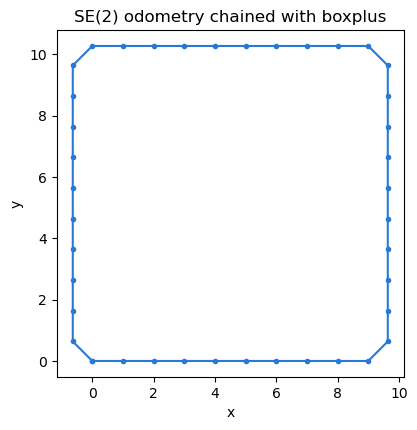

ok   the loop closes on itself


In [10]:
import matplotlib.pyplot as plt

pose = SE2(0.0, np.zeros(2))
path = [pose.t_flat]
for k in range(40):
    turn = np.pi / 2 if k % 10 == 9 else 0.0
    pose = pose.boxplus(np.array([1.0, 0.0, turn]))
    path.append(pose.t_flat)
path = np.array(path)

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(path[:, 0], path[:, 1], "-o", color="#2a78d6", ms=3, lw=1.5)
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title("SE(2) odometry chained with boxplus")
plt.show()
check("the loop closes on itself", np.allclose(path[-1], path[0], atol=1e-9))

All checks passed if this notebook ran to the end.